# Next-Day PM2.5 Forecast — Proof of Concept (PurpleAir + SIMA)

**Objetivo.** Demostrar que, con los datos que ya captura el proyecto, se puede pronosticar el PM2.5 promedio del **día siguiente** en cada monitor y en cada AGEB, y medir **qué tan confiable** es ese pronóstico.

**Enfoque.**
1. **Unidad de pronóstico:** el monitor (sensor PurpleAir o estación SIMA), no el AGEB. Los valores por AGEB son interpolados y no son observaciones independientes. El pronóstico de los monitores se lleva después a los AGEBs con interpolación lineal.
2. **Datos:** lecturas horarias de PurpleAir (con control de calidad y corrección EPA del script de producción) y de SIMA. Se calculan promedios diarios por monitor, con humedad y temperatura.
3. **Panel combinado:** todos los monitores en un solo conjunto de entrenamiento (monitor × día). Así se suman cientos de ejemplos aunque solo haya unas semanas de datos.
4. **Modelos:** tres líneas base y dos modelos.
   - Persistencia: mañana = hoy.
   - Persistencia de red: mañana = mediana de la red hoy.
   - Climatología: promedio histórico del monitor.
   - Regresión lineal.
   - *Gradient boosting*.
5. **Validación temporal (*rolling origin*):** para pronosticar el día *T*, el modelo solo se entrena con días anteriores a *T*, como pasaría en operación.
6. **Confianza:**
   - *Skill score* frente a la persistencia, con IC 95 % por *bootstrap* de días: **> 0 significa que el modelo le gana a "mañana = hoy"**.
   - Intervalo de predicción del 80 % por **predicción conforme**, construido con los errores de días anteriores, y su cobertura real.
   - Aciertos y falsas alarmas para días por encima de la guía de la OMS.

**Limitaciones (prueba de concepto).**
- Solo hay ~1 mes de datos de otoño y unas 4 lecturas por día (el cron no es horario). Los promedios diarios son aproximados.
- No se usa pronóstico meteorológico del día siguiente; solo condiciones observadas hoy.
- Un modelo operativo necesita al menos un año continuo de datos horarios y pronóstico meteorológico (capa de mezcla, viento).

In [1]:
# =============================================================================
# BLOCK 0 · Setup: libraries, plot style and helpers
# =============================================================================
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.interpolate import LinearNDInterpolator

try:
    from sklearn.linear_model import LinearRegression
    from sklearn.ensemble import HistGradientBoostingRegressor
except ImportError as e:
    raise ImportError("Instala scikit-learn en el Python del notebook:  %pip install scikit-learn") from e

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.titlesize": 20,
    "axes.grid": False,
})

OFFSET_HORAS = {"PurpleAir": -6, "SIMA": 0}   # PurpleAir se registra en UTC; SIMA en hora local
MIN_LECTURAS_DIA = 2                          # lecturas mínimas para el promedio diario de un monitor
MIN_DIAS_ENTRENAMIENTO = 10                   # días de entrenamiento antes de empezar a pronosticar
NIVEL_INTERVALO = 0.80                        # intervalo de predicción (predicción conforme)
MIN_RESIDUOS = 50                             # errores previos mínimos para construir el intervalo
N_BOOT = 1000
SEMILLA = 42
WHO_24H, NOM_24H = 15, 25                     # µg/m³: guía OMS 2021 y NOM-025-SSA1-2021 (etapa vigente)

COLOR_RED = {"PurpleAir": "#eb6834", "SIMA": "#2a78d6"}
COLOR_NEUTRO = "#4D4D4D"
COLOR_SIN_DATO = "#E6E9F1"
MODELOS = {                                   # columna de predicción -> etiqueta en inglés
    "pred_persistencia": "Persistence",
    "pred_red": "Network persistence",
    "pred_climatologia": "Climatology",
    "pred_lineal": "Linear regression",
    "pred_gb": "Gradient boosting",
}
COLOR_MODELO = dict(zip(MODELOS.values(), ["#9e9e9e", "#bdbdbd", "#d9d9d9", "#1baf7a", "#4a2a8f"]))
CLASES_PRONOSTICO = {
    f"Below WHO guideline (≤ {WHO_24H})": "#1baf7a",
    f"Above WHO, below NOM ({WHO_24H}–{NOM_24H})": "#f2b134",
    f"Above NOM-025 (> {NOM_24H})": "#c62828",
}

# Variables de entrada (todas conocidas al cierre del día de emisión del pronóstico)
VARS_LINEAL = ["pm25", "red_hoy", "hr", "temp", "finde_obj", "es_sima"]
VARS_GB = VARS_LINEAL + ["pm25_max", "pm25_ayer", "clim_monitor"]
NOMBRES_VARS = {
    "pm25": "PM2.5 today (monitor)", "red_hoy": "PM2.5 today (network median)", "hr": "Relative humidity today",
    "temp": "Temperature today", "finde_obj": "Target day is weekend", "es_sima": "SIMA station (flag)",
    "pm25_max": "Max PM2.5 today", "pm25_ayer": "PM2.5 yesterday", "clim_monitor": "Monitor mean to date",
}


def encontrar_raiz(inicio=Path.cwd()):
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "SIMA").is_dir() and (carpeta / "Purple Air").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró la raíz del proyecto (carpetas 'SIMA' y 'Purple Air').")


RAIZ = encontrar_raiz()
DIR_FIGURAS = Path("figuras_forecast")
DIR_RESULTADOS = Path("resultados_forecast")
DIR_FIGURAS.mkdir(exist_ok=True)
DIR_RESULTADOS.mkdir(exist_ok=True)


def banner(titulo, ancho=70):
    print("\n" + "=" * ancho + f"\n {titulo}\n" + "=" * ancho)


def cierre(ancho=70):
    print("=" * ancho + "\n")


def tabla(df, decimales=2):
    print(df.round(decimales).to_string())


def nueva_figura(filas, columnas, figsize):
    fig, axes = plt.subplots(filas, columnas, figsize=figsize, facecolor="white", squeeze=False)
    for ax in axes.flat:
        ax.set_facecolor("white")
        for spine in ax.spines.values():
            spine.set_color("black")
            spine.set_linewidth(1.2)
    return fig, axes


def leyenda(ax, loc="best", **kw):
    ax.legend(loc=loc, frameon=True, edgecolor="black", **kw)


def guardar(fig, nombre):
    fig.savefig(DIR_FIGURAS / f"{nombre}.png", dpi=300, bbox_inches="tight", facecolor="white")


def anillos_exteriores(geometria):
    partes = [geometria["coordinates"]] if geometria["type"] == "Polygon" else geometria["coordinates"]
    return [np.asarray(p[0])[:, :2] for p in partes]


def dibujar_agebs(ax, geometrias, colores, borde="white", grosor=0.15, zorder=1):
    poligonos, caras = [], []
    for g, c in zip(geometrias, colores):
        for anillo in anillos_exteriores(g):
            poligonos.append(anillo)
            caras.append(c)
    ax.add_collection(PolyCollection(poligonos, facecolors=caras, edgecolors=borde, linewidths=grosor, zorder=zorder))


def encuadrar(ax, geometrias, margen=0.01):
    xy = np.vstack([a for g in geometrias for a in anillos_exteriores(g)])
    ax.set_xlim(xy[:, 0].min() - margen, xy[:, 0].max() + margen)
    ax.set_ylim(xy[:, 1].min() - margen, xy[:, 1].max() + margen)
    ax.set_aspect(1 / np.cos(np.radians(xy[:, 1].mean())))
    ax.set_axis_off()


print(f"Project root: {RAIZ}")

Project root: c:\Users\betor\Desktop\Capa de Meteorologia


In [2]:
# =============================================================================
# BLOCK 1 · Data loading: hourly readings (QC + EPA correction) and daily means per monitor
# =============================================================================
# --- PurpleAir: mismas funciones de control de calidad y corrección que el script de producción ---
sys.path.insert(0, str(RAIZ / "Purple Air"))
import interpolacion_calidadaire_ageb as ia

pa = ia.leer_historial_sensores(RAIZ / "Purple Air" / "purpleair_meteo_historico.csv")
motivo = ia.control_calidad(pa)
pa_ok = ia.corregir_lecturas(pa, motivo)
lect_pa = pd.DataFrame({
    "monitor": "PA-" + pa_ok["sensor_index"].astype(str),
    "red": "PurpleAir",
    "t": pd.to_datetime(pa_ok["t"], utc=True).dt.tz_localize(None) + pd.Timedelta(hours=OFFSET_HORAS["PurpleAir"]),
    "pm25": pa_ok["PM25_ugm3"],
    "hr": pa_ok["Humedad_pct"].where(pa_ok["Humedad_pct"].between(1, 99)),
    "temp": (pd.to_numeric(pa_ok.get("temperatura_F"), errors="coerce") - 32) * 5 / 9,
    "lat": pa_ok["lat"], "lon": pa_ok["lon"],
})

# --- SIMA: lecturas horarias por estación (−9999 = sin dato) ---------------------------------------
sima = pd.read_csv(RAIZ / "SIMA" / "sima_meteo_historico.csv", encoding="utf-8-sig", na_values=[-9999, "-9999", "ND"])
lect_sima = pd.DataFrame({
    "monitor": "SIMA-" + sima["Estacion"].astype(str).str.strip(),
    "red": "SIMA",
    "t": pd.to_datetime(sima["timestamp"], errors="coerce") + pd.Timedelta(hours=OFFSET_HORAS["SIMA"]),
    "pm25": pd.to_numeric(sima["PM25_ugm3"], errors="coerce"),
    "hr": pd.to_numeric(sima["Humedad_pct"], errors="coerce"),
    "temp": pd.to_numeric(sima["Temperatura_C"], errors="coerce"),
    "lat": sima["lat"], "lon": sima["lon"],
})
lect_sima = lect_sima[lect_sima["pm25"].between(0, 500)]

# --- Promedios diarios por monitor ----------------------------------------------------------------
lecturas = pd.concat([lect_pa, lect_sima], ignore_index=True).dropna(subset=["t", "pm25"])
lecturas["t"] = lecturas["t"].dt.floor("h")
lecturas = lecturas.drop_duplicates(["monitor", "t"], keep="last")
lecturas["dia"] = lecturas["t"].dt.normalize()
diario = (lecturas.groupby(["monitor", "red", "dia"])
          .agg(pm25=("pm25", "mean"), pm25_max=("pm25", "max"), n_lect=("pm25", "size"),
               hr=("hr", "mean"), temp=("temp", "mean"), lat=("lat", "median"), lon=("lon", "median"))
          .reset_index())
diario = diario[diario["n_lect"] >= MIN_LECTURAS_DIA].reset_index(drop=True)

banner("DATA SUMMARY")
print("-- PurpleAir quality control (hourly readings) --")
tabla(motivo.replace("", "valid").value_counts().rename("readings").to_frame(), 0)
print("\n-- Daily means per monitor (days with at least "
      f"{MIN_LECTURAS_DIA} readings) --")
resumen = diario.assign(dia=diario["dia"].dt.strftime("%Y-%m-%d")).groupby("red").agg(monitors=("monitor", "nunique"), monitor_days=("dia", "size"),
                                    first_day=("dia", "min"), last_day=("dia", "max"),
                                    readings_per_day=("n_lect", "median"), mean_pm25=("pm25", "mean"))
tabla(resumen, 1)
cierre()


 DATA SUMMARY
-- PurpleAir quality control (hourly readings) --
            readings
valid          12032
congelado       1015
sin_senal        465
interiores       144
pico              20

-- Daily means per monitor (days with at least 2 readings) --
           monitors  monitor_days   first_day    last_day  readings_per_day  mean_pm25
red                                                                                   
PurpleAir        93          2754  2026-10-16  2026-11-17               4.0       11.9
SIMA             15           324  2026-10-27  2026-11-17               4.0       13.0



## Training set: one row per monitor and day

Cada fila describe el **día de emisión** *d* de un monitor y su objetivo es el PM2.5 promedio del **día siguiente** (*d* + 1) en ese mismo monitor. Solo se usan pares de días consecutivos.

| Variable | Qué representa |
|---|---|
| PM2.5 hoy, máximo de hoy, PM2.5 de ayer | Persistencia local |
| Mediana de la red hoy | Señal regional (los episodios afectan a toda la ciudad) |
| Humedad y temperatura de hoy | Condiciones meteorológicas observadas |
| Promedio del monitor hasta hoy | Nivel típico del sitio |
| Fin de semana (día objetivo), estación SIMA | Calendario y tipo de monitor |

In [3]:
# =============================================================================
# BLOCK 2 · Training set: features today, target tomorrow
# =============================================================================
d = diario.sort_values(["monitor", "dia"]).reset_index(drop=True)
d["red_hoy"] = d.groupby(["red", "dia"])["pm25"].transform("median")
previo = d.groupby("monitor")[["dia", "pm25"]].shift(1)
d["pm25_ayer"] = previo["pm25"].where(d["dia"] - previo["dia"] == pd.Timedelta(days=1))
d["clim_monitor"] = d.groupby("monitor")["pm25"].transform(lambda s: s.expanding().mean())
d["es_sima"] = (d["red"] == "SIMA").astype(int)
d["dia_obj"] = d["dia"] + pd.Timedelta(days=1)

objetivo = d[["monitor", "dia", "pm25"]].rename(columns={"dia": "dia_obj", "pm25": "y"})
datos = d.merge(objetivo, on=["monitor", "dia_obj"], how="inner")
datos["finde_obj"] = (datos["dia_obj"].dt.dayofweek >= 5).astype(int)
datos = datos.sort_values(["dia_obj", "monitor"]).reset_index(drop=True)

banner("TRAINING SET (MONITOR × DAY PAIRS)")
tabla(datos.groupby("red").agg(pairs=("y", "size"), monitors=("monitor", "nunique"),
                               target_days=("dia_obj", "nunique"), mean_target=("y", "mean")), 1)
print("\n-- Correlation of tomorrow's PM2.5 with today's variables (Spearman) --")
cor = datos[VARS_GB].corrwith(datos["y"], method="spearman").sort_values(ascending=False)
for v, r in cor.items():
    print(f"{NOMBRES_VARS[v]:<32}: {r:+.2f}")
cierre()


 TRAINING SET (MONITOR × DAY PAIRS)
           pairs  monitors  target_days  mean_target
red                                                 
PurpleAir   2650        89           32         12.2
SIMA         305        15           21         13.0

-- Correlation of tomorrow's PM2.5 with today's variables (Spearman) --
PM2.5 today (monitor)           : +0.52
Monitor mean to date            : +0.51
PM2.5 yesterday                 : +0.47
Max PM2.5 today                 : +0.47
PM2.5 today (network median)    : +0.45
Temperature today               : +0.14
SIMA station (flag)             : +0.07
Target day is weekend           : +0.06
Relative humidity today         : +0.05



## Rolling-origin evaluation and confidence

Para cada día objetivo *T* (después de `MIN_DIAS_ENTRENAMIENTO` días), los modelos se entrenan **solo con días anteriores a *T*** y pronostican *T*. Así cada error medido es un error "fuera de muestra", igual que en operación.

**Métricas.**
- **RMSE, MAE y sesgo** (µg/m³).
- **r:** correlación entre pronóstico y observación.
- **Skill score = 1 − MSE_modelo / MSE_persistencia.** Mayor que 0: el modelo le gana a "mañana = hoy". IC 95 % remuestreando días.
- **Intervalo del 80 %** por predicción conforme: para el día *T* se usa el percentil 80 del error absoluto de los pronósticos de días anteriores. Se reporta su **cobertura real** (debería acercarse al 80 %).
- **Días por encima de la guía de la OMS (15 µg/m³):** probabilidad de detección (POD) y razón de falsas alarmas (FAR).

In [4]:
# =============================================================================
# BLOCK 3 · Rolling-origin evaluation: baselines vs models, skill and confidence
# =============================================================================
def nuevo_gb():
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                         min_samples_leaf=20, l2_regularization=1.0, random_state=SEMILLA)


def ajustar_predecir(train, test):
    """Entrena regresión lineal y gradient boosting con 'train' y pronostica 'test'."""
    medianas = train[VARS_LINEAL].median()
    lin = LinearRegression().fit(train[VARS_LINEAL].fillna(medianas), train["y"])
    gb = nuevo_gb().fit(train[VARS_GB], train["y"])
    return (np.clip(lin.predict(test[VARS_LINEAL].fillna(medianas)), 0, None),
            np.clip(gb.predict(test[VARS_GB]), 0, None), lin, gb)


dias_obj = np.sort(datos["dia_obj"].unique())
bloques = []
for T in dias_obj:
    train, test = datos[datos["dia_obj"] < T], datos[datos["dia_obj"] == T].copy()
    if train["dia_obj"].nunique() < MIN_DIAS_ENTRENAMIENTO or test.empty:
        continue
    test["pred_lineal"], test["pred_gb"], *_ = ajustar_predecir(train, test)
    bloques.append(test)
pred = pd.concat(bloques, ignore_index=True)
pred["pred_persistencia"] = pred["pm25"]
pred["pred_red"] = pred["red_hoy"]
pred["pred_climatologia"] = pred["clim_monitor"]

# --- Intervalos de predicción conformes (solo con errores de días anteriores) ---------------------
for col in ("pred_lineal", "pred_gb"):
    err = (pred["y"] - pred[col]).abs()
    q = pd.Series(np.nan, index=pred.index)
    for T in np.sort(pred["dia_obj"].unique()):
        previos = err[pred["dia_obj"] < T]
        if len(previos) >= MIN_RESIDUOS:
            q[pred["dia_obj"] == T] = np.quantile(previos, NIVEL_INTERVALO)
    pred[f"{col}_lo"] = np.clip(pred[col] - q, 0, None)
    pred[f"{col}_hi"] = pred[col] + q

# --- Métricas -----------------------------------------------------------------------------------
rng = np.random.default_rng(SEMILLA)


def metricas(df, col):
    e = df[col] - df["y"]
    e_p = df["pred_persistencia"] - df["y"]
    # skill con IC: remuestreo de días completos
    por_dia = pd.DataFrame({"dia": df["dia_obj"], "se": e ** 2, "se_p": e_p ** 2}).groupby("dia").sum()
    idx = rng.integers(0, len(por_dia), size=(N_BOOT, len(por_dia)))
    skill_boot = 1 - por_dia["se"].to_numpy()[idx].sum(axis=1) / por_dia["se_p"].to_numpy()[idx].sum(axis=1)
    return {"n": len(df), "RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)), "bias": np.mean(e),
            "r": np.corrcoef(df[col], df["y"])[0, 1],
            "skill": 1 - np.mean(e ** 2) / np.mean(e_p ** 2),
            "skill_lo": np.percentile(skill_boot, 2.5), "skill_hi": np.percentile(skill_boot, 97.5)}


evaluacion = pd.DataFrame([{"network": red, "model": nombre, **metricas(g, col)}
                           for red, g in [("All monitors", pred), *pred.groupby("red")]
                           for col, nombre in MODELOS.items()]).set_index(["network", "model"])

eventos = []
for red, g in [("All monitors", pred), *pred.groupby("red")]:
    obs = g["y"] > WHO_24H
    for col, nombre in MODELOS.items():
        prev = g[col] > WHO_24H
        aciertos = (obs & prev).sum()
        eventos.append({"network": red, "model": nombre, "observed_events": int(obs.sum()),
                        "POD": aciertos / max(obs.sum(), 1), "FAR": (prev & ~obs).sum() / max(prev.sum(), 1),
                        "accuracy": (obs == prev).mean()})
eventos = pd.DataFrame(eventos).set_index(["network", "model"])

cobertura = []
for red, g in [("All monitors", pred), *pred.groupby("red")]:
    for col, nombre in (("pred_lineal", "Linear regression"), ("pred_gb", "Gradient boosting")):
        ok = g[f"{col}_lo"].notna()
        dentro = g.loc[ok, "y"].between(g.loc[ok, f"{col}_lo"], g.loc[ok, f"{col}_hi"])
        cobertura.append({"network": red, "model": nombre, "n": int(ok.sum()), "coverage_pct": 100 * dentro.mean(),
                          "mean_width": (g.loc[ok, f"{col}_hi"] - g.loc[ok, f"{col}_lo"]).mean()})
cobertura = pd.DataFrame(cobertura).set_index(["network", "model"])

todos = evaluacion.loc["All monitors"]
mejor = todos.loc[["Linear regression", "Gradient boosting"], "RMSE"].idxmin()
COL_MEJOR = {v: k for k, v in MODELOS.items()}[mejor]

banner("ROLLING-ORIGIN EVALUATION · NEXT-DAY MEAN PM2.5")
print(f"Forecast days evaluated: {pred['dia_obj'].nunique()} "
      f"({pd.Timestamp(pred['dia_obj'].min()):%Y-%m-%d} to {pd.Timestamp(pred['dia_obj'].max()):%Y-%m-%d}) "
      f"| forecasts: {len(pred):,}")
print("\n-- Accuracy (µg/m³) and skill vs persistence (95% CI by day bootstrap) --")
tabla(evaluacion, 2)
print(f"\n-- Days above the WHO 24-h guideline ({WHO_24H} µg/m³) --")
tabla(eventos, 2)
print(f"\n-- {int(NIVEL_INTERVALO * 100)} % prediction intervals (conformal): real coverage --")
tabla(cobertura, 1)
r = todos.loc[mejor]
veredicto = ("beats persistence (CI above 0)" if r["skill_lo"] > 0 else
             "is worse than persistence (CI below 0)" if r["skill_hi"] < 0 else
             "is not distinguishable from persistence (CI includes 0)")
print(f"\nBest model: {mejor} | RMSE {r['RMSE']:.2f} µg/m³ vs persistence "
      f"{todos.loc['Persistence', 'RMSE']:.2f} | skill {r['skill']:+.2f} "
      f"[{r['skill_lo']:+.2f}, {r['skill_hi']:+.2f}] -> the model {veredicto}.")
cierre()


 ROLLING-ORIGIN EVALUATION · NEXT-DAY MEAN PM2.5
Forecast days evaluated: 22 (2026-10-27 to 2026-11-17) | forecasts: 2,100

-- Accuracy (µg/m³) and skill vs persistence (95% CI by day bootstrap) --
                                     n  RMSE   MAE  bias     r  skill  skill_lo  skill_hi
network      model                                                                       
All monitors Persistence          2100  8.66  6.82 -0.11  0.27   0.00      0.00      0.00
             Network persistence  2100  8.73  6.95 -0.13  0.11  -0.02     -0.13      0.11
             Climatology          2100  8.48  7.07 -4.64  0.23   0.04     -0.47      0.39
             Linear regression    2100  8.09  6.51 -1.00  0.19   0.13     -0.02      0.26
             Gradient boosting    2100  8.18  6.50  0.11  0.23   0.11     -0.24      0.35
PurpleAir    Persistence          1795  8.90  7.05 -0.13  0.26   0.00      0.00      0.00
             Network persistence  1795  9.01  7.19 -0.17  0.10  -0.03     -0.14  

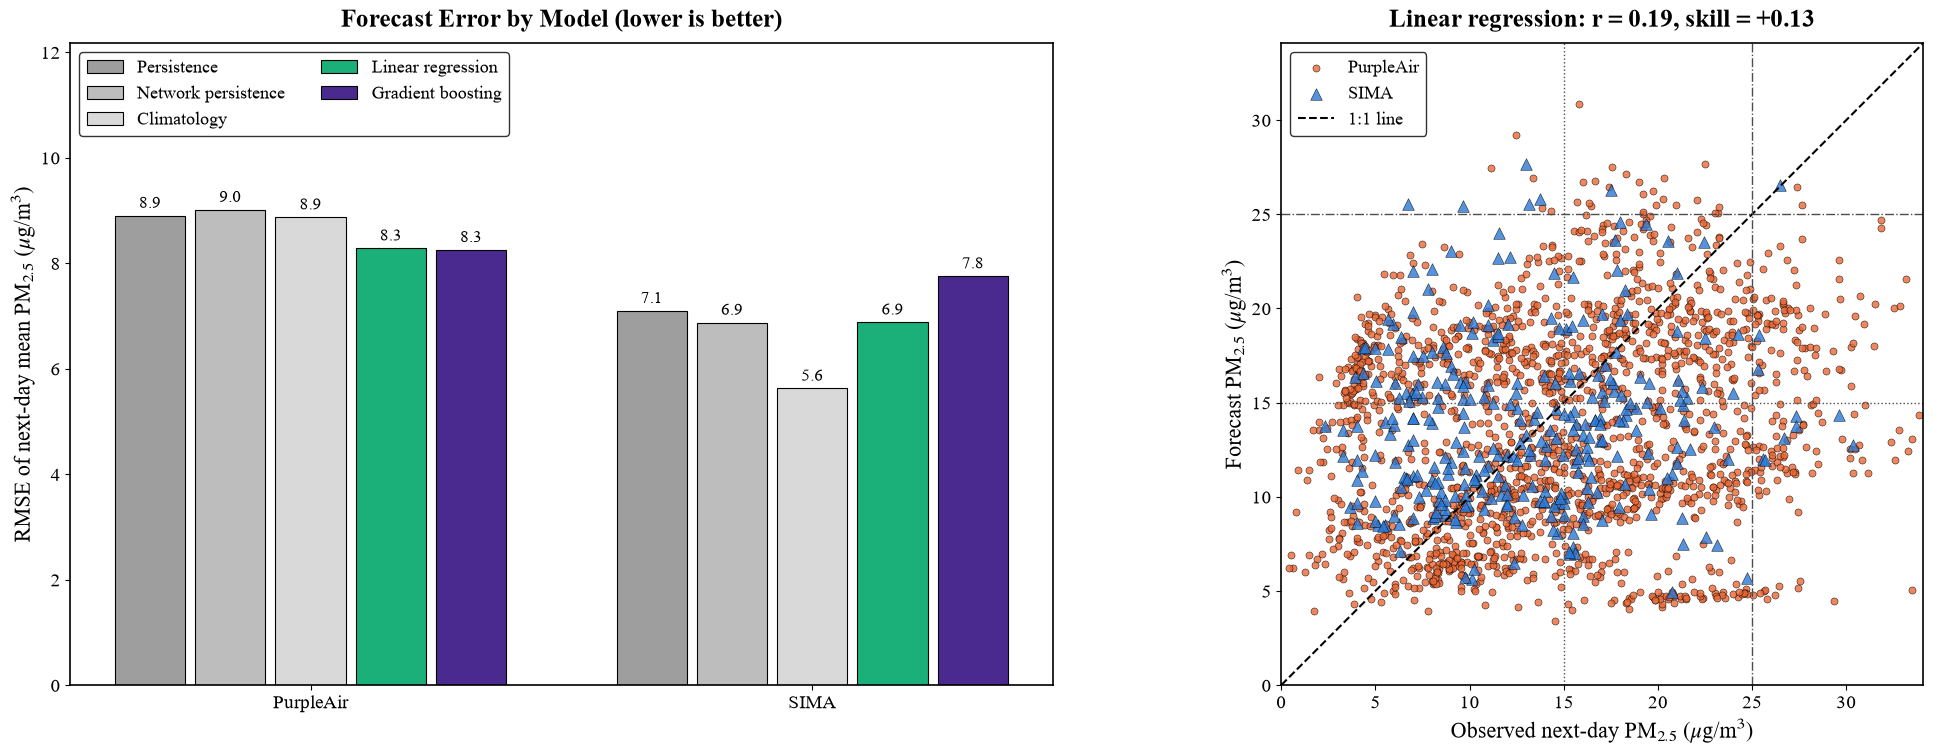

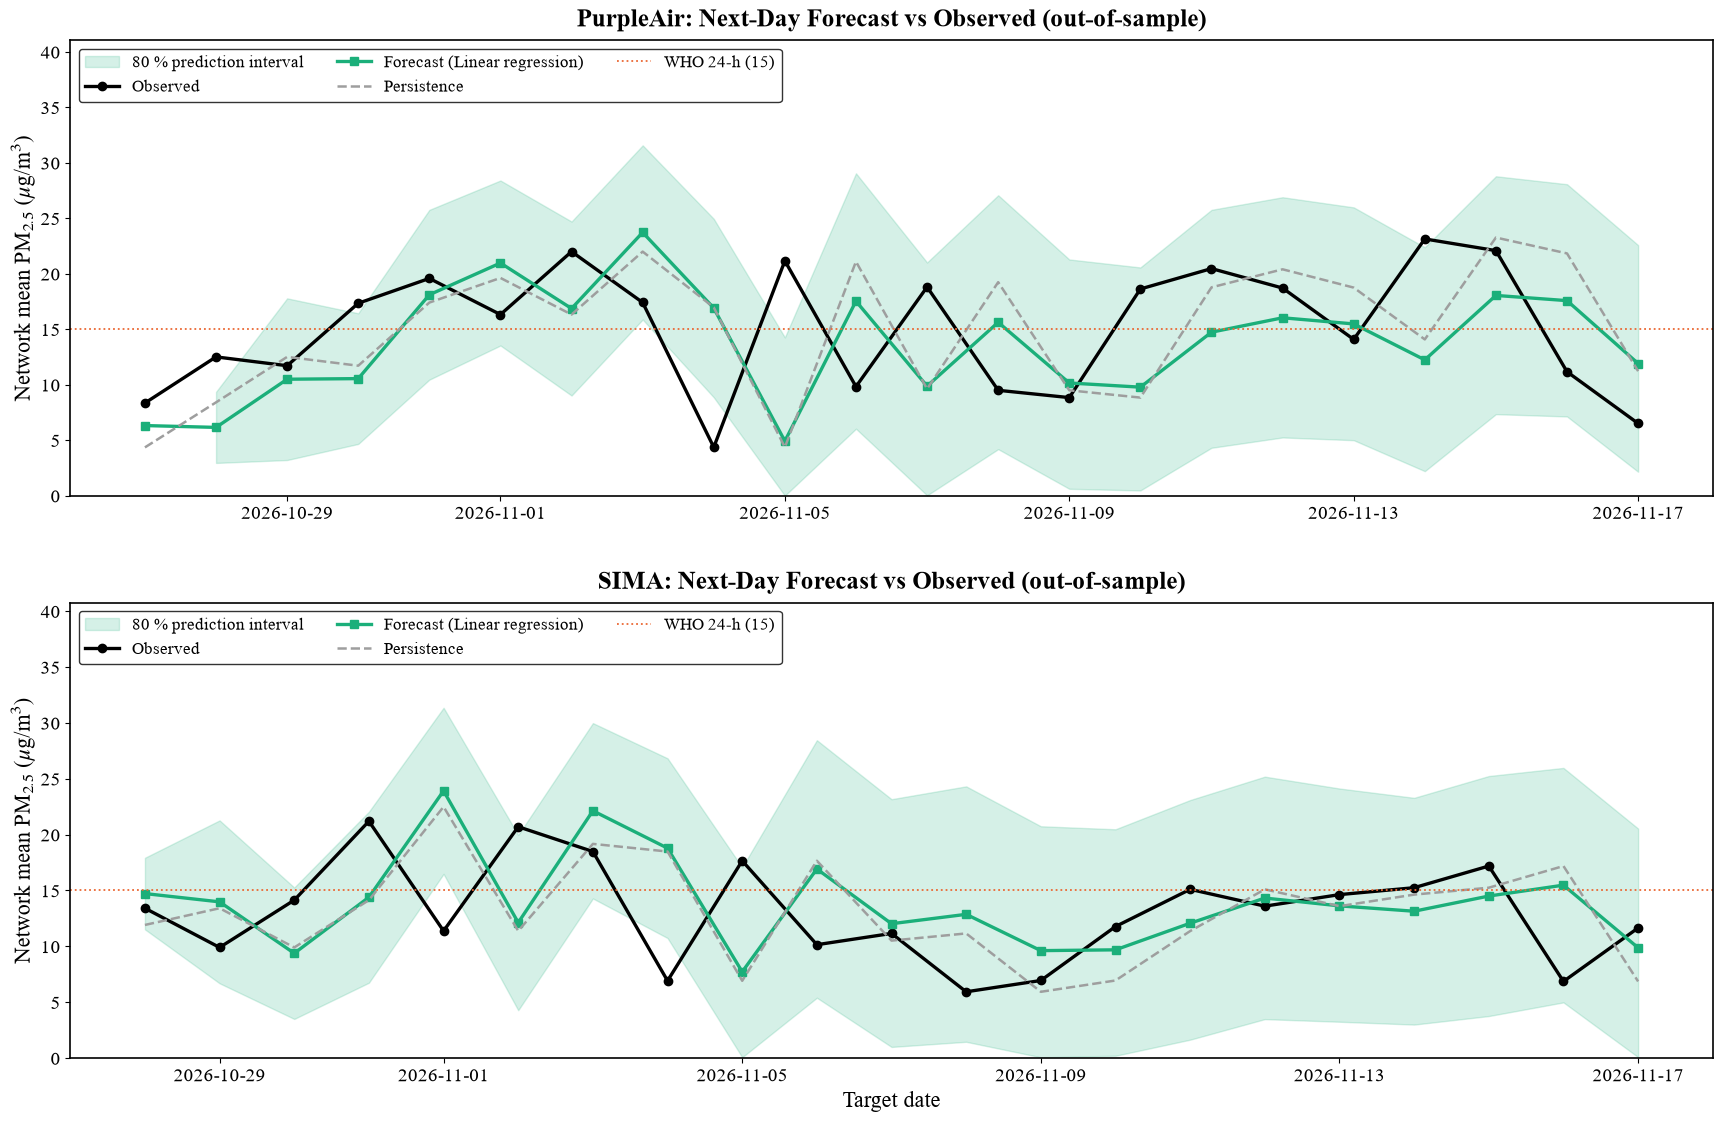

In [5]:
# =============================================================================
# BLOCK 4 · Figures: model skill, observed vs forecast, and daily time series
# =============================================================================
# --- Figura 1: RMSE por modelo y red + dispersión del mejor modelo ---
fig, axes = nueva_figura(1, 2, (22, 8.5))
ax = axes[0, 0]
redes = ["PurpleAir", "SIMA"]
x = np.arange(len(redes))
ancho = 0.16
for k, nombre in enumerate(MODELOS.values()):
    valores = [evaluacion.loc[(red, nombre), "RMSE"] if (red, nombre) in evaluacion.index else np.nan for red in redes]
    barras = ax.bar(x + (k - 2) * ancho, valores, width=ancho - 0.02, color=COLOR_MODELO[nombre],
                    edgecolor="black", linewidth=0.8, label=nombre)
    ax.bar_label(barras, labels=[f"{v:.1f}" for v in valores], padding=3, fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(redes)
ax.set_ylabel(r"RMSE of next-day mean PM$_{2.5}$ ($\mu$g/m$^3$)")
ax.set_ylim(0, np.nanmax(evaluacion["RMSE"].to_numpy()) * 1.35)
ax.set_title("Forecast Error by Model (lower is better)", fontweight="bold", pad=12)
leyenda(ax, loc="upper left", ncol=2, fontsize=13)

ax = axes[0, 1]
for red in redes:
    g = pred[pred["red"] == red]
    ax.scatter(g["y"], g[COL_MEJOR], s=26 if red == "PurpleAir" else 70, marker="o" if red == "PurpleAir" else "^",
               color=COLOR_RED[red], edgecolor="black", linewidth=0.4, alpha=0.8, label=red)
tope = np.nanpercentile(np.r_[pred["y"], pred[COL_MEJOR]], 99.5) * 1.1
ax.plot([0, tope], [0, tope], color="black", lw=1.5, linestyle="--", label="1:1 line")
for v, est in ((WHO_24H, ":"), (NOM_24H, "-.")):
    ax.axvline(v, color=COLOR_NEUTRO, lw=1, linestyle=est)
    ax.axhline(v, color=COLOR_NEUTRO, lw=1, linestyle=est)
ax.set_xlim(0, tope)
ax.set_ylim(0, tope)
ax.set_aspect("equal")
r = evaluacion.loc[("All monitors", mejor)]
ax.set_xlabel(r"Observed next-day PM$_{2.5}$ ($\mu$g/m$^3$)")
ax.set_ylabel(r"Forecast PM$_{2.5}$ ($\mu$g/m$^3$)")
ax.set_title(f"{mejor}: r = {r['r']:.2f}, skill = {r['skill']:+.2f}", fontweight="bold", pad=12)
leyenda(ax, loc="upper left", fontsize=13)
plt.tight_layout(pad=3.0)
guardar(fig, "fc1_model_skill")
plt.show()

# --- Figura 2: serie diaria, promedio de la red, observado vs pronóstico con intervalo del 80 % ---
fig, axes = nueva_figura(2, 1, (18, 12))
for ax, red in zip(axes[:, 0], redes):
    g = pred[pred["red"] == red].groupby("dia_obj")[["y", "pred_persistencia", COL_MEJOR,
                                                    f"{COL_MEJOR}_lo", f"{COL_MEJOR}_hi"]].mean()
    ax.fill_between(g.index, g[f"{COL_MEJOR}_lo"], g[f"{COL_MEJOR}_hi"], color=COLOR_MODELO[mejor], alpha=0.18,
                    label=f"{int(NIVEL_INTERVALO * 100)} % prediction interval")
    ax.plot(g.index, g["y"], color="black", lw=2.4, marker="o", ms=6, label="Observed")
    ax.plot(g.index, g[COL_MEJOR], color=COLOR_MODELO[mejor], lw=2.4, marker="s", ms=6, label=f"Forecast ({mejor})")
    ax.plot(g.index, g["pred_persistencia"], color="#9e9e9e", lw=1.8, linestyle="--", label="Persistence")
    ax.axhline(WHO_24H, color=COLOR_RED["PurpleAir"], lw=1.3, linestyle=":", label=f"WHO 24-h ({WHO_24H})")
    ax.set_ylabel(r"Network mean PM$_{2.5}$ ($\mu$g/m$^3$)")
    ax.set_ylim(0, max(g[["y", f"{COL_MEJOR}_hi"]].max().max(), WHO_24H) * 1.3)
    ax.set_title(f"{red}: Next-Day Forecast vs Observed (out-of-sample)", fontweight="bold", pad=10)
    leyenda(ax, loc="upper left", ncol=3, fontsize=12)
axes[-1, 0].set_xlabel("Target date")
plt.tight_layout(pad=2.5)
guardar(fig, "fc2_forecast_time_series")
plt.show()

## Tomorrow's forecast by AGEB

1. El mejor modelo se reentrena con **todos** los días disponibles.
2. Pronostica el día siguiente al último día completo de datos en cada monitor.
3. El pronóstico se lleva a los AGEBs con interpolación lineal (Delaunay) en su centroide, como en el pipeline.

**Probabilidad de rebasar la guía de la OMS:** fracción de errores históricos fuera de muestra con los que *pronóstico + error* > 15 µg/m³. Es una medida directa de la confianza del pronóstico en cada zona.


 FORECAST FOR 2026-11-18 (issued with data of 2026-11-17)
Model: Linear regression | monitors used: 95 (PurpleAir 80, SIMA 15)
Network mean forecast: 9.5 µg/m³ (80 % interval ±10.7 µg/m³ per monitor)
AGEBs with forecast: 1,535
                              AGEBs
clase                              
Below WHO guideline (≤ 15)     1515
Above WHO, below NOM (15–25)     20
Above NOM-025 (> 25)              0

Mean probability of exceeding the WHO guideline across AGEBs: 38 %



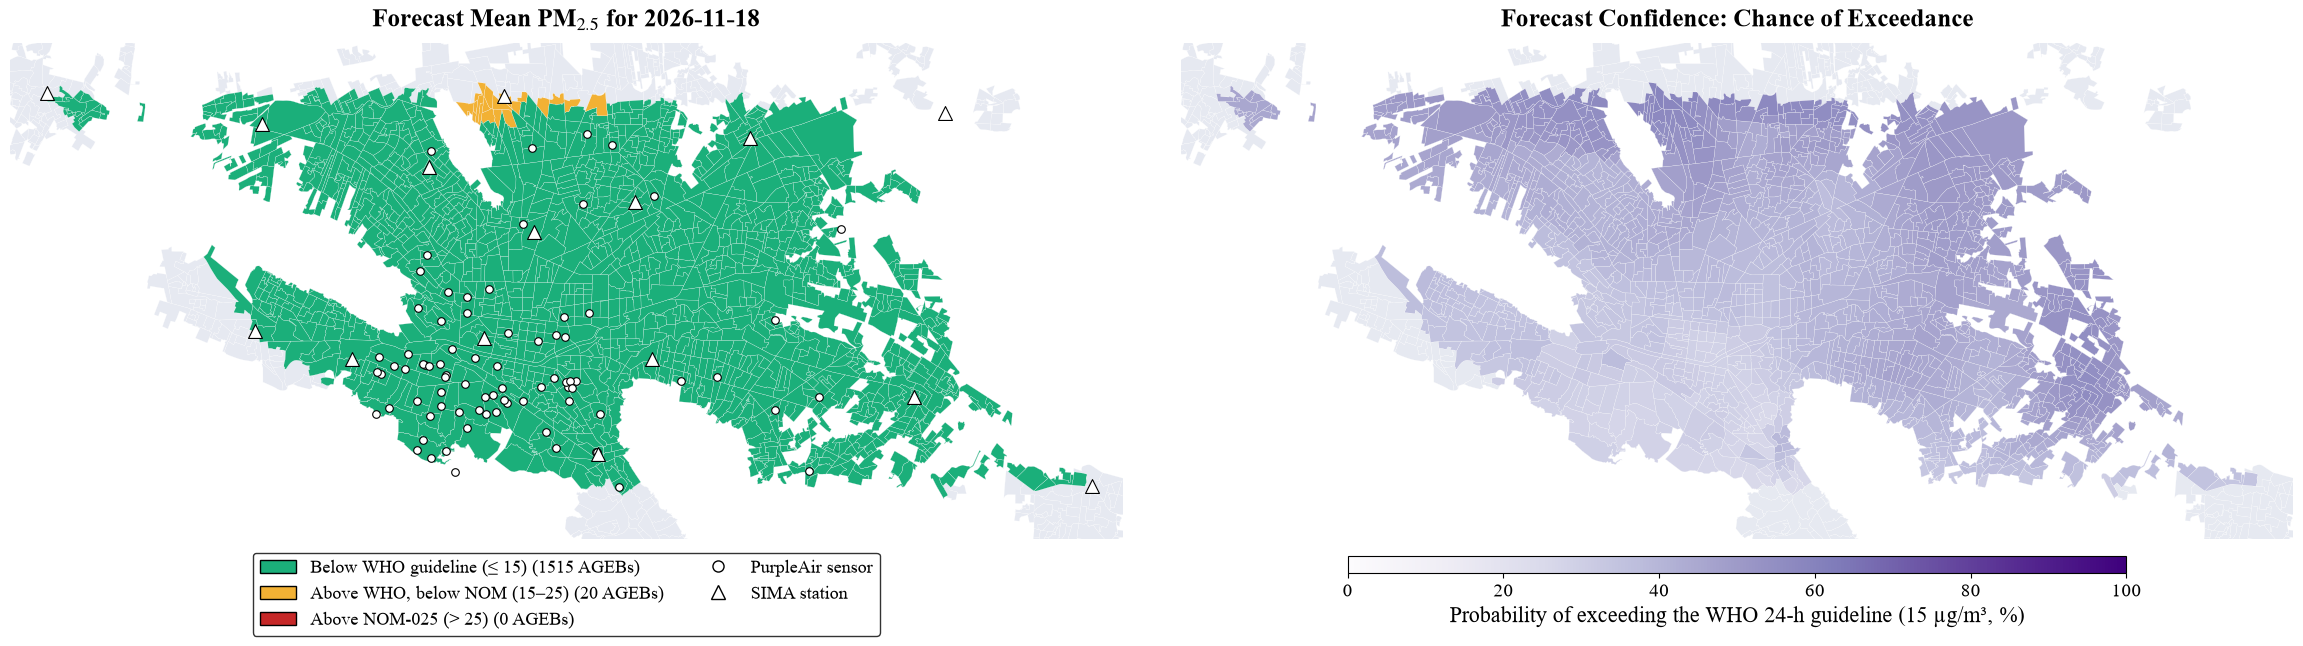

In [6]:
# =============================================================================
# BLOCK 5 · Tomorrow's forecast by monitor and by AGEB, with confidence
# =============================================================================
# --- 1. Modelo final con todos los datos -------------------------------------------------------
_, _, lin_final, gb_final = ajustar_predecir(datos, datos.head(1))
modelo_final = lin_final if mejor == "Linear regression" else gb_final
vars_final = VARS_LINEAL if mejor == "Linear regression" else VARS_GB
medianas_final = datos[VARS_LINEAL].median()

# Último día "completo": al menos la mitad de los monitores activos tienen promedio diario
cobertura_dia = d.groupby("dia")["monitor"].nunique()
dia_emision = cobertura_dia[cobertura_dia >= 0.5 * cobertura_dia.max()].index.max()
dia_pronostico = dia_emision + pd.Timedelta(days=1)
hoy = d[d["dia"] == dia_emision].copy()
hoy["finde_obj"] = int(dia_pronostico.dayofweek >= 5)
X = hoy[vars_final].fillna(medianas_final) if mejor == "Linear regression" else hoy[vars_final]
hoy["pronostico"] = np.clip(modelo_final.predict(X), 0, None)

errores = (pred["y"] - pred[COL_MEJOR]).to_numpy()
q = np.quantile(np.abs(errores), NIVEL_INTERVALO)
hoy["lo"], hoy["hi"] = np.clip(hoy["pronostico"] - q, 0, None), hoy["pronostico"] + q
hoy["prob_who"] = [(p + errores > WHO_24H).mean() for p in hoy["pronostico"]]

# --- 2. Interpolación a AGEBs (centroides) --------------------------------------------------------
def centroide(geometria):
    partes = [geometria["coordinates"]] if geometria["type"] == "Polygon" else geometria["coordinates"]
    suma_a = suma_x = suma_y = 0.0
    for anillos in partes:
        for k, anillo in enumerate(anillos):
            p = np.asarray(anillo, dtype=float)
            x_, y_ = p[:, 0], p[:, 1]
            cruz = x_[:-1] * y_[1:] - x_[1:] * y_[:-1]
            a = cruz.sum() / 2
            if a == 0:
                continue
            cx, cy = ((x_[:-1] + x_[1:]) * cruz).sum() / (6 * a), ((y_[:-1] + y_[1:]) * cruz).sum() / (6 * a)
            a = abs(a) * (1 if k == 0 else -1)
            suma_a += a; suma_x += cx * a; suma_y += cy * a
    return (suma_x / suma_a, suma_y / suma_a) if suma_a else (np.nan, np.nan)


with open(RAIZ / "Purple Air" / "AQ_PM25_v2.geojson", encoding="utf-8") as f:
    feats = json.load(f)["features"]
agebs = pd.DataFrame({"cvegeo": [str(ft["properties"].get("Clave Geográfica (CVEGEO)", "")).zfill(13) for ft in feats],
                      "geometry": [ft["geometry"] for ft in feats]}).drop_duplicates("cvegeo").reset_index(drop=True)
agebs[["lon", "lat"]] = pd.DataFrame([centroide(g) for g in agebs["geometry"]], index=agebs.index)
puntos = hoy[["lon", "lat"]].to_numpy()
for col in ("pronostico", "lo", "hi", "prob_who"):
    agebs[col] = LinearNDInterpolator(puntos, hoy[col].to_numpy())(agebs[["lon", "lat"]].to_numpy())
etiquetas = list(CLASES_PRONOSTICO)
agebs["clase"] = pd.cut(agebs["pronostico"], [-np.inf, WHO_24H, NOM_24H, np.inf], labels=etiquetas)
con_dato = agebs[agebs["pronostico"].notna()]

banner(f"FORECAST FOR {dia_pronostico:%Y-%m-%d} (issued with data of {dia_emision:%Y-%m-%d})")
print(f"Model: {mejor} | monitors used: {len(hoy)} "
      f"(PurpleAir {int((hoy['red'] == 'PurpleAir').sum())}, SIMA {int((hoy['red'] == 'SIMA').sum())})")
print(f"Network mean forecast: {hoy['pronostico'].mean():.1f} µg/m³ "
      f"({int(NIVEL_INTERVALO * 100)} % interval ±{q:.1f} µg/m³ per monitor)")
print(f"AGEBs with forecast: {len(con_dato):,}")
tabla(con_dato["clase"].value_counts().reindex(etiquetas).rename("AGEBs").to_frame(), 0)
print(f"\nMean probability of exceeding the WHO guideline across AGEBs: {100 * con_dato['prob_who'].mean():.0f} %")
cierre()

# --- 3. Figura: mapa del pronóstico y de la probabilidad de rebasar la guía ---
fig, axes = nueva_figura(1, 2, (24, 11))
ax = axes[0, 0]
dibujar_agebs(ax, agebs["geometry"], [COLOR_SIN_DATO] * len(agebs), zorder=0)
dibujar_agebs(ax, con_dato["geometry"], con_dato["clase"].astype(str).map(CLASES_PRONOSTICO))
for red, marcador in (("PurpleAir", "o"), ("SIMA", "^")):
    g = hoy[hoy["red"] == red]
    ax.scatter(g["lon"], g["lat"], marker=marcador, s=30 if red == "PurpleAir" else 100, color="white",
               edgecolor="black", linewidth=0.8, zorder=5)
encuadrar(ax, con_dato["geometry"], margen=0.02)
conteo = con_dato["clase"].value_counts()
handles = [Patch(facecolor=c, edgecolor="black", label=f"{e} ({conteo.get(e, 0)} AGEBs)") for e, c in CLASES_PRONOSTICO.items()]
handles += [Line2D([], [], marker="o", ls="", color="white", mec="black", ms=8, label="PurpleAir sensor"),
            Line2D([], [], marker="^", ls="", color="white", mec="black", ms=10, label="SIMA station")]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=2, frameon=True, edgecolor="black",
          fontsize=13)
ax.set_title(f"Forecast Mean PM$_{{2.5}}$ for {dia_pronostico:%Y-%m-%d}", fontweight="bold", pad=12)

ax = axes[0, 1]
dibujar_agebs(ax, agebs["geometry"], [COLOR_SIN_DATO] * len(agebs), zorder=0)
mapa = plt.get_cmap("Purples")
dibujar_agebs(ax, con_dato["geometry"], [mapa(0.1 + 0.85 * v) for v in con_dato["prob_who"]])
encuadrar(ax, con_dato["geometry"], margen=0.02)
sm = plt.cm.ScalarMappable(cmap=mapa, norm=plt.Normalize(0, 100))
cb = fig.colorbar(sm, cax=ax.inset_axes([0.15, -0.07, 0.70, 0.035]), orientation="horizontal")
cb.set_label(f"Probability of exceeding the WHO 24-h guideline ({WHO_24H} µg/m³, %)")
ax.set_title("Forecast Confidence: Chance of Exceedance", fontweight="bold", pad=12)
plt.tight_layout(pad=3.0)
guardar(fig, "fc3_tomorrow_forecast_map")
plt.show()

In [7]:
# =============================================================================
# BLOCK 6 · Conclusions for the proof of concept and export
# =============================================================================
r = evaluacion.loc[("All monitors", mejor)]
p = evaluacion.loc[("All monitors", "Persistence")]
c = cobertura.loc[("All monitors", mejor)]
e = eventos.loc[("All monitors", mejor)]

banner("PROOF-OF-CONCEPT SUMMARY")
print(f"1. Data: {datos['monitor'].nunique()} monitors, {datos['dia_obj'].nunique()} target days, "
      f"{len(datos):,} monitor-day pairs; {pred['dia_obj'].nunique()} days forecast out-of-sample.")
print(f"2. Accuracy: {mejor} RMSE {r['RMSE']:.1f} µg/m³ (persistence {p['RMSE']:.1f}); "
      f"skill vs persistence {r['skill']:+.2f} [95% CI {r['skill_lo']:+.2f}, {r['skill_hi']:+.2f}].")
print(f"3. Confidence: the {int(NIVEL_INTERVALO * 100)} % interval (±{c['mean_width'] / 2:.1f} µg/m³) "
      f"contained the observed value {c['coverage_pct']:.0f} % of the time.")
print(f"4. Alerts (WHO {WHO_24H} µg/m³): detected {100 * e['POD']:.0f} % of exceedance days, "
      f"false-alarm ratio {100 * e['FAR']:.0f} %.")
print("5. Limits: ~1 month of autumn data, ~4 readings per day, no meteorological forecast as input.")
print("   Next steps: continuous hourly capture, ≥ 1 year of history, and forecast weather (mixing height, wind).")
cierre()

pred.to_csv(DIR_RESULTADOS / "pronosticos_fuera_de_muestra.csv", index=False, encoding="utf-8-sig")
evaluacion.to_csv(DIR_RESULTADOS / "evaluacion_modelos.csv", encoding="utf-8-sig")
hoy[["monitor", "red", "lat", "lon", "pm25", "pronostico", "lo", "hi", "prob_who"]].to_csv(
    DIR_RESULTADOS / f"pronostico_monitores_{dia_pronostico:%Y%m%d}.csv", index=False, encoding="utf-8-sig")
agebs[["cvegeo", "pronostico", "lo", "hi", "prob_who", "clase"]].to_csv(
    DIR_RESULTADOS / f"pronostico_agebs_{dia_pronostico:%Y%m%d}.csv", index=False, encoding="utf-8-sig")
print(f"Tables saved to '{DIR_RESULTADOS}' and figures to '{DIR_FIGURAS}'.")


 PROOF-OF-CONCEPT SUMMARY
1. Data: 104 monitors, 32 target days, 2,955 monitor-day pairs; 22 days forecast out-of-sample.
2. Accuracy: Linear regression RMSE 8.1 µg/m³ (persistence 8.7); skill vs persistence +0.13 [95% CI -0.02, +0.26].
3. Confidence: the 80 % interval (±9.0 µg/m³) contained the observed value 70 % of the time.
4. Alerts (WHO 15 µg/m³): detected 49 % of exceedance days, false-alarm ratio 47 %.
5. Limits: ~1 month of autumn data, ~4 readings per day, no meteorological forecast as input.
   Next steps: continuous hourly capture, ≥ 1 year of history, and forecast weather (mixing height, wind).

Tables saved to 'resultados_forecast' and figures to 'figuras_forecast'.
